<a href="https://colab.research.google.com/github/mshitie/quantitative_XAI/blob/main/BUS_UCLM_quantitative_XAI_v8_colab_robust.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BUS-UCLM-only quantitative XAI evaluation (Google Colab) - v8 (Colab-robust: Drive saving, resumable, faster) / v7 (balanced split, macro-F1 selection, validation-tuned class bias, auto-saved results)

# Quantitative XAI on BUS-UCLM Breast Ultrasound

Train, validate, test, and evaluate explanations using **BUS-UCLM only**. No BUSI download, BUSI training, or BUSI-vs-external comparison is performed.

Three-class classification: benign / malignant / normal. XAI: Grad-CAM, Grad-CAM++, LayerCAM, Integrated Gradients, optional RISE, random-map and centre-prior baselines.

BUS-UCLM RGB masks define labels (red=malignant, green=benign, all-black=normal) and lesion regions (all non-black pixels). Verify the inferred patient grouping before interpreting patient-level confidence intervals.

In [1]:

# ============================================================
# BUS-UCLM: Download from Kaggle and Extract
# Kaggle: mulugetashitie/bus-uclm
# Destination: /content/bus_uclm
# ============================================================

!pip install -q kaggle

import os
import glob
import zipfile
import shutil

# 1. Configure Kaggle API credentials
KAGGLE_JSON = "/content/kaggle.json"

if not os.path.exists(KAGGLE_JSON):
    from google.colab import files
    print("Upload your Kaggle API token (kaggle.json):")
    uploaded = files.upload()

    if "kaggle.json" not in uploaded:
        raise FileNotFoundError("kaggle.json was not uploaded.")

os.makedirs("/root/.kaggle", exist_ok=True)
shutil.copy(KAGGLE_JSON, "/root/.kaggle/kaggle.json")
os.chmod("/root/.kaggle/kaggle.json", 0o600)

# 2. Dataset configuration
DATASET = "mulugetashitie/bus-uclm"
DOWNLOAD_DIR = "/content"
UCLM_ROOT = "/content/bus_uclm"

# 3. Download dataset from Kaggle
if not os.path.isdir(UCLM_ROOT) or not os.listdir(UCLM_ROOT):
    print("Downloading BUS-UCLM from Kaggle...")

    !kaggle datasets download -d {DATASET} -p {DOWNLOAD_DIR} --force

    # 4. Locate downloaded ZIP
    zip_files = glob.glob("/content/bus-uclm.zip")

    if not zip_files:
        raise FileNotFoundError("BUS-UCLM ZIP file was not downloaded.")

    ZIP_PATH = zip_files[0]

    # 5. Extract dataset
    os.makedirs(UCLM_ROOT, exist_ok=True)

    print("Extracting BUS-UCLM...")
    with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(UCLM_ROOT)

    print("Extraction completed.")

else:
    print("BUS-UCLM directory already exists. Skipping download.")

# 6. Find images and masks directories
image_dirs = glob.glob(
    f"{UCLM_ROOT}/**/images", recursive=True
)

mask_dirs = glob.glob(
    f"{UCLM_ROOT}/**/masks", recursive=True
)

print("\n========== BUS-UCLM DATASET CHECK ==========")
print("Dataset root:", UCLM_ROOT)
print("Image directories:", image_dirs)
print("Mask directories:", mask_dirs)

if not image_dirs or not mask_dirs:
    print("\nWARNING: Could not automatically locate both images and masks.")
    print("Top-level contents:", os.listdir(UCLM_ROOT)[:30])
else:
    print("\nSUCCESS: Images and masks directories found.")

# 7. Display extracted files
print("\nColab files:", os.listdir("/content")[:30])


Upload your Kaggle API token (kaggle.json):


Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/mulugetashitie/bus-uclm
License(s): unknown
100% 321M/321M [00:03<00:00, 92.3MB/s]

Extracting BUS-UCLM...
Extraction completed.

========== BUS-UCLM DATASET CHECK ==========
Dataset root: /content/bus_uclm
Image directories: ['/content/bus_uclm/BUS-UCLM/images']
Mask directories: ['/content/bus_uclm/BUS-UCLM/masks']

SUCCESS: Images and masks directories found.

Colab files: ['.config', 'kaggle.json', 'bus-uclm.zip', 'bus_uclm', 'sample_data']


In [2]:
import os, glob, random, warnings, time, pickle
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
# Memory growth MUST be set before the GPU is first used (otherwise restart the runtime).
for _g in tf.config.list_physical_devices("GPU"):
    try:
        tf.config.experimental.set_memory_growth(_g, True)
    except RuntimeError as e:
        print("Could not set memory growth (restart the runtime and run this cell first):", e)
from tensorflow.keras import layers, models, optimizers, callbacks
from tensorflow.keras.applications import ResNet50, DenseNet121, VGG16
from tensorflow.keras.applications import resnet50, densenet, vgg16
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score, auc,
                             accuracy_score, f1_score)
from sklearn.utils.class_weight import compute_class_weight
from scipy.stats import spearmanr, wilcoxon

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

# ------------------------------- CONFIG -------------------------------
BACKBONE = "resnet50"            # "resnet50" | "densenet121" | "vgg16"
DATA_ROOT = "/content"   # recursively locate BUS-UCLM images/ and masks/
CLASSES = ["benign", "malignant", "normal"]
IMG_SIZE, BATCH = 384, 16      # v5: even higher resolution (lesions are small: median 6% of the image); use 320 if OOM
MAX_PER_CLASS = None             # e.g. 150 for a quick smoke test
N_EVAL_PER_CLASS = 30            # None = evaluate XAI on EVERY test image
N_NOISE = 3                      # noisy copies per image for the stability metric
N_BOOT = 2000                    # bootstrap resamples for confidence intervals
USE_RISE, N_RISE = True, 200     # RISE is slow: set USE_RISE=False for a fast run
N_SANITY = 15                    # images for the parameter-randomization test
EPOCHS_HEAD, EPOCHS_FT = 10, 40  # v4: phase-1 (head only) and phase-2 (fine-tuning) max epochs
LR_HEAD, LR_FT = 1e-3, 5e-5      # v5: phase-2 peak LR (lower because more layers are unfrozen), cosine-decayed
TRAIN_BN = True                  # v4: BatchNorm adapts to ultrasound statistics during fine-tuning
USE_MID_LAYERCAM = True          # v4: LayerCAM on an intermediate layer (higher-res map); False = last conv as in v3
RUN_CV = False                    # v4: True = also train/evaluate all 6 folds (classification only, slow)
PRED_BS = 32                     # max images per forward pass in the XAI/metric code (lower it if OOM persists)
N_NOISE_RISE = 2                # v8: RISE is ~500x costlier per call, so use fewer noisy copies for its stability test
IG_STEPS, IG_CHUNK = 32, 8       # Integrated Gradients: path steps and images per backward pass
CALIBRATE_BIAS = True            # v7: tune per-class logit bias on the VALIDATION set (boosts malignant sensitivity)
LABEL_SMOOTH = 0.1              # v5: label smoothing (less over-confident, better generalisation)
WEIGHT_DECAY = 1e-4             # v5: AdamW weight decay
USE_TTA = True                  # v5: test-time augmentation (average of original + horizontal flip)
DUP_HAMMING = 6                  # dHash Hamming distance (of 256 bits) treated as duplicate

BACKBONES = {
    "resnet50":    dict(cls=ResNet50,    prep=resnet50.preprocess_input,    last_conv="conv5_block3_out", mid_conv="conv4_block6_out",  unfreeze=["conv3", "conv4", "conv5"]),
    "densenet121": dict(cls=DenseNet121, prep=densenet.preprocess_input, last_conv="relu",             mid_conv="conv4_block24_concat", unfreeze=["conv3", "conv4", "conv5"]),
    "vgg16":       dict(cls=VGG16,       prep=vgg16.preprocess_input,       last_conv="block5_conv3",     mid_conv="block4_conv3",  unfreeze=["block3", "block4", "block5"]),
}
CFG = BACKBONES[BACKBONE]
preprocess_input = CFG["prep"]
# ---- v5: ONE output folder for every table (.csv) and figure (.png); zipped + downloaded in the last cell ----
# v8: everything (tables, figures, model, checkpoints) lives on Google Drive so a disconnect never loses work
USE_DRIVE = True
BASE_DIR = "."
if USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        BASE_DIR = "/content/drive/MyDrive/BUS_UCLM_xai"
    except Exception as e:
        print("Drive not mounted, using local disk (NOT persistent):", e)
OUT_DIR = os.path.join(BASE_DIR, "BUS_UCLM_results")
MODEL_DIR = os.path.join(BASE_DIR, "BUS_UCLM_models")   # the (large) model file is kept OUT of the results folder
os.makedirs(OUT_DIR, exist_ok=True); os.makedirs(MODEL_DIR, exist_ok=True)
OUT = os.path.join(OUT_DIR, f"xai_BUS_UCLM_{BACKBONE}")     # prefix of every file written by this notebook

def save_fig(name, dpi=200):
    """Save the current matplotlib figure into OUT_DIR (call before plt.show())."""
    path = os.path.join(OUT_DIR, name)
    plt.savefig(path, dpi=dpi, bbox_inches="tight"); print("saved ->", path)

def save_table(d, name, index=True):
    """Save a DataFrame as CSV into OUT_DIR."""
    path = os.path.join(OUT_DIR, name)
    d.to_csv(path, index=index); print("saved ->", path)

# Neutral-gray image in the model's input space (XAI baseline / 'deleted pixel' value) and the
# input-space change per +1 raw pixel level (used to scale noise in the stability test).
GRAY = preprocess_input(np.full((IMG_SIZE, IMG_SIZE, 3), 127.5, "float32"))
SCALE = preprocess_input(np.full((IMG_SIZE, IMG_SIZE, 3), 128.5, "float32")) - GRAY
print("Backbone:", BACKBONE, "| GPU:", tf.config.list_physical_devices("GPU"))
if not tf.config.list_physical_devices("GPU"):
    print("!!! NO GPU: Runtime > Change runtime type > T4 GPU. On CPU this notebook is 20-50x slower and will time out.")

Drive not mounted, using local disk (NOT persistent): Error: credential propagation was unsuccessful
Backbone: resnet50 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
# ===================== BUS-UCLM dataset indexing and patient-level split =====================
import re
IMG_EXT = (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")
MIN_MASK_PIX = 20

def locate_bus_uclm(root="/content"):
    found = []
    for dp, dn, fn in os.walk(root):
        low = {d.lower(): d for d in dn}
        if "images" in low and "masks" in low:
            found.append((0 if "uclm" in dp.lower() else 1,
                          os.path.join(dp, low["images"]), os.path.join(dp, low["masks"])))
    if not found:
        raise FileNotFoundError("No paired images/ and masks/ directories found under /content. Extract BUS-UCLM first.")
    found.sort(key=lambda z:z[0])
    return found[0][1], found[0][2]

IMG_DIR, MASK_DIR = locate_bus_uclm(DATA_ROOT)
print("Images:", IMG_DIR, "\nMasks:", MASK_DIR)
def stem(p): return os.path.splitext(os.path.basename(p))[0].lower()
def mask_colour_counts(p):
    m=cv2.imread(p, cv2.IMREAD_COLOR)
    if m is None: return None
    rgb=m[...,::-1].astype(np.int16); r,g,b=rgb[...,0],rgb[...,1],rgb[...,2]
    return (int(((r>100)&(r>g+50)&(r>b+50)).sum()),
            int(((g>100)&(g>r+50)&(g>b+50)).sum()),
            int((rgb.max(-1)>50).sum()))
def patient_id_from_path(p):
    # Default convention: first filename token. Edit if BUS-UCLM filenames encode IDs differently.
    return re.split(r"[_\-\s]", os.path.splitext(os.path.basename(p))[0])[0]

image_paths=sorted(p for p in glob.glob(os.path.join(IMG_DIR,"**","*"),recursive=True) if p.lower().endswith(IMG_EXT))
mask_paths=[p for p in glob.glob(os.path.join(MASK_DIR,"**","*"),recursive=True) if p.lower().endswith(IMG_EXT)]
mask_lookup={stem(p):p for p in mask_paths}
rows=[]; skipped=[]
for p in image_paths:
    s=stem(p); mp=mask_lookup.get(s) or mask_lookup.get(s+"_mask")
    if mp is None:
        skipped.append((os.path.basename(p),"matching mask not found")); continue
    counts=mask_colour_counts(mp)
    if counts is None:
        skipped.append((os.path.basename(p),"mask unreadable")); continue
    red,green,anypix=counts
    if red>=MIN_MASK_PIX: label="malignant"
    elif green>=MIN_MASK_PIX: label="benign"
    elif anypix<MIN_MASK_PIX: label="normal"
    else:
        skipped.append((os.path.basename(p),"unrecognized mask colour")); continue
    rows.append(dict(path=p,mask_path=mp,label=label,group=patient_id_from_path(p),
                     mixed_colours=bool(red>=MIN_MASK_PIX and green>=MIN_MASK_PIX)))
df=pd.DataFrame(rows)
assert len(df)>0,"No paired BUS-UCLM images and masks found."
label2idx={c:i for i,c in enumerate(CLASSES)}
df["y"]=df.label.map(label2idx).astype(int)
print(f"Usable images: {len(df)} | inferred groups: {df.group.nunique()} | skipped: {len(skipped)}")
print("Class counts:",df.label.value_counts().reindex(CLASSES,fill_value=0).to_dict())
if skipped: print("Skipped examples:",skipped[:10])
if df.mixed_colours.any(): print("Warning: mixed red/green masks:",int(df.mixed_colours.sum()),"(assigned malignant).")
if df.group.nunique()>0.8*len(df): print("WARNING: inferred IDs are almost image-level; inspect patient_id_from_path().")
# v6: patient groups have very uneven sizes, so a single random StratifiedGroupKFold can give a fold with
# almost no malignant images (e.g. 6). We try many seeds and keep the split whose folds best match the overall
# class proportions and sizes. The criterion uses ONLY labels/groups (never model performance), so it is leak-free.
print("Group size summary (images per inferred patient):", df.groupby("group").size().describe().round(1).to_dict())
_exp = np.bincount(df.y.values, minlength=len(CLASSES)) / 6.0
def split_score(fs):
    s = 0.0
    for te in fs:
        c = np.bincount(df.y.values[te], minlength=len(CLASSES))
        s += (np.abs(c - _exp) / _exp).max()               # worst relative class-count error in this fold
    return s
best_s, best_seed, folds = 1e9, SEED, None
for _s in range(300):
    _f = [te for _, te in StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=_s).split(df, df.y, df.group)]
    _sc = split_score(_f)
    if _sc < best_s: best_s, best_seed, folds = _sc, _s, _f
print(f"Balanced split chosen: seed {best_seed} (imbalance score {best_s:.2f})")
print(pd.DataFrame([np.bincount(df.y.values[te], minlength=len(CLASSES)) for te in folds], columns=CLASSES).rename_axis("fold"))
test_df=df.iloc[folds[0]].reset_index(drop=True)
val_df=df.iloc[folds[1]].reset_index(drop=True)
train_df=df.iloc[np.concatenate(folds[2:])].reset_index(drop=True)
assert not(set(train_df.group)&set(test_df.group)) and not(set(val_df.group)&set(test_df.group)) and not(set(train_df.group)&set(val_df.group))
for nm,d in [("train",train_df),("validation",val_df),("test",test_df)]:
    print(nm,len(d),d.label.value_counts().to_dict())
save_table(df.drop(columns="mixed_colours"), "BUS_UCLM_dataset_labels.csv", index=False)
_split = pd.concat([train_df.assign(split="train"), val_df.assign(split="validation"), test_df.assign(split="test")])
save_table(_split[["path","label","group","split"]], "BUS_UCLM_splits.csv", index=False)
save_table(pd.crosstab(_split.split, _split.label).reindex(columns=CLASSES, fill_value=0), "BUS_UCLM_split_class_counts.csv")


Images: /content/bus_uclm/BUS-UCLM/images 
Masks: /content/bus_uclm/BUS-UCLM/masks
Usable images: 683 | inferred groups: 38 | skipped: 0
Class counts: {'benign': 174, 'malignant': 90, 'normal': 419}
Group size summary (images per inferred patient): {'count': 38.0, 'mean': 18.0, 'std': 9.1, 'min': 3.0, '25%': 12.0, '50%': 16.5, '75%': 24.8, 'max': 39.0}
Balanced split chosen: seed 7 (imbalance score 1.75)
      benign  malignant  normal
fold                           
0         27         19      74
1         26         20      67
2         33         13      93
3         23         17      68
4         34         12      55
5         31          9      62
train 450 {'normal': 278, 'benign': 121, 'malignant': 51}
validation 113 {'normal': 67, 'benign': 26, 'malignant': 20}
test 120 {'normal': 74, 'benign': 27, 'malignant': 19}
saved -> ./BUS_UCLM_results/BUS_UCLM_dataset_labels.csv
saved -> ./BUS_UCLM_results/BUS_UCLM_splits.csv
saved -> ./BUS_UCLM_results/BUS_UCLM_split_class_counts.cs

In [4]:
AUTOTUNE = tf.data.AUTOTUNE
aug = tf.keras.Sequential([layers.RandomFlip("horizontal"),
                           layers.RandomRotation(0.08),
                           layers.RandomZoom(0.15),
                           layers.RandomTranslation(0.08, 0.08),
                           layers.RandomContrast(0.25),      # intensity/contrast variation between scanners
                           layers.RandomBrightness(0.15, value_range=(0, 255))])

def load_img(path):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    return tf.image.resize(img, (IMG_SIZE, IMG_SIZE))               # float32, 0-255

def make_ds(d, training=False):
    # v5: decoded images are cached in RAM (much faster epochs); labels are one-hot (needed for label smoothing)
    ds = tf.data.Dataset.from_tensor_slices((d.path.values, d.y.values))
    ds = ds.map(lambda p, y: (tf.cast(tf.round(load_img(p)), tf.uint8), tf.one_hot(y, len(CLASSES))), num_parallel_calls=AUTOTUNE).cache()   # v8: uint8 cache = 4x less RAM
    ds = ds.map(lambda x, y: (tf.cast(x, tf.float32), y), num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.shuffle(len(d), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH)
    if training:
        ds = ds.map(lambda x, y: (aug(x, training=True), y), num_parallel_calls=AUTOTUNE)
    ds = ds.map(lambda x, y: (preprocess_input(x), y), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

def predict_ds(m, ds, tta=USE_TTA):
    """Class probabilities for a (non-shuffled) dataset; optional test-time augmentation (horizontal flip)."""
    p = m.predict(ds, verbose=0)
    if tta:
        flipped = ds.map(lambda x, y: (tf.image.flip_left_right(x), y))
        p = (p + m.predict(flipped, verbose=0)) / 2.0
    return p / p.sum(1, keepdims=True)

train_ds, val_ds, test_ds = make_ds(train_df, True), make_ds(val_df), make_ds(test_df)


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 104s 2s/step - accuracy: 0.4133 - loss: 1.8100 - val_accuracy: 0.1858 - val_loss: 1.3089 - val_macro_f1: 0.1132 - val_bal_acc: 0.2614
Epoch 2/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 23s 745ms/step - accuracy: 0.4600 - loss: 1.1870 - val_accuracy: 0.1947 - val_loss: 1.2866 - val_macro_f1: 0.1835 - val_bal_acc: 0.3162
Epoch 3/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 22s 722ms/step - accuracy: 0.5644 - loss: 0.9927 - val_accuracy: 0.6106 - val_loss: 1.0022 - val_macro_f1: 0.4432 - val_bal_acc: 0.5265
Epoch 4/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 23s 751ms/step - accuracy: 0.6200 - loss: 0.9256 - val_accuracy: 0.1947 - val_loss: 1.5923 - val_macro_f1: 0.1494 - val_bal_acc: 0.3590
Epoch 5/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 23s 753ms/step - accuracy: 0.5133 - loss: 1.1292 - val_accuracy: 0.6814 - val_loss: 0.9452 - val_macro_f1: 0.6040 - val_bal_acc: 0.6135
Epoch 6/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 22s 716ms/step - accuracy: 0.6600 - loss: 0

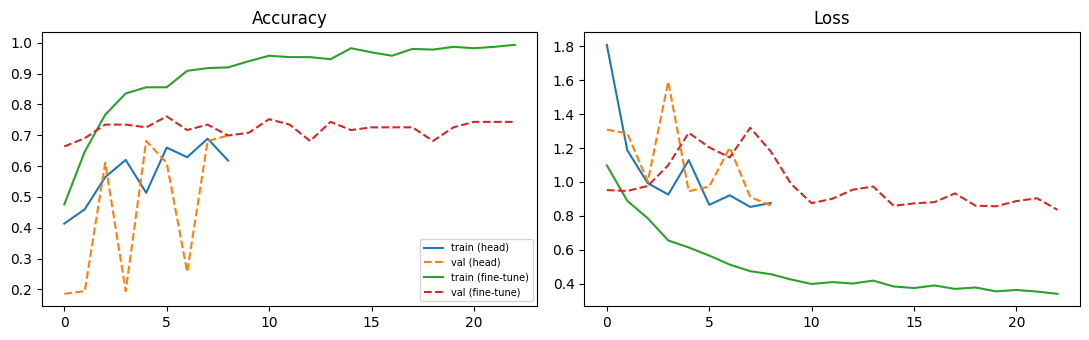

saved -> ./BUS_UCLM_results/xai_BUS_UCLM_resnet50_training_history.csv


In [5]:
import gc
from sklearn.metrics import balanced_accuracy_score

def build_model():
    base_ = CFG["cls"](weights="imagenet", include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
    x = layers.GlobalAveragePooling2D()(base_.output)
    x = layers.Dense(512, activation="relu")(x)
    x = layers.Dropout(0.4)(x)
    logits = layers.Dense(len(CLASSES), name="logits")(x)       # explanations are computed on these logits
    out = layers.Softmax(name="probs")(logits)
    return models.Model(base_.input, out, name=f"{BACKBONE}_busi"), base_

def set_trainable(base_, prefixes, train_bn):
    """Unfreeze backbone layers whose name starts with one of `prefixes` (empty list = all frozen)."""
    for l in base_.layers:
        on = any(l.name.startswith(p) for p in prefixes)
        l.trainable = on and (train_bn or not isinstance(l, layers.BatchNormalization))

class MacroF1Select(callbacks.Callback):
    """v6: model selection / early stopping on validation MACRO-F1 (not accuracy, which the 'normal' class dominates).
    Restores the best weights at the end of training and logs val_macro_f1 / val_bal_acc."""
    def __init__(self, ds, y, patience):
        super().__init__(); self.ds, self.y, self.patience = ds, np.asarray(y), patience
    def on_train_begin(self, logs=None):
        self.best, self.wait, self.best_w = -1.0, 0, None
    def on_epoch_end(self, epoch, logs=None):
        p = self.model.predict(self.ds, verbose=0).argmax(1)
        f1 = f1_score(self.y, p, average="macro"); logs["val_macro_f1"] = f1
        logs["val_bal_acc"] = balanced_accuracy_score(self.y, p)
        if f1 > self.best + 1e-4:
            self.best, self.wait, self.best_w = f1, 0, self.model.get_weights()
        else:
            self.wait += 1
            if self.wait >= self.patience:
                self.model.stop_training = True
    def on_train_end(self, logs=None):
        if self.best_w is not None:
            self.model.set_weights(self.best_w)

def make_opt(lr):
    try:
        return optimizers.AdamW(lr, weight_decay=WEIGHT_DECAY)
    except AttributeError:
        return optimizers.Adam(lr)

def calibrate_class_bias(m, va_df, grid=np.arange(-1.0, 3.01, 0.25)):
    """v7: the model under-detects the rare 'malignant' class (many called 'normal'). Search an additive logit bias
    for benign/malignant (normal fixed at 0) that maximises VALIDATION macro-F1, then bake it into the 'logits'
    layer so predictions, probabilities AND all XAI methods use the same calibrated model. Test data is never used."""
    lp = np.log(predict_ds(m, make_ds(va_df)) + 1e-8); yv = va_df.y.values
    best_s, best_b = -1.0, np.zeros(len(CLASSES))
    for b0 in grid:
        for b1 in grid:
            b = np.array([b0, b1, 0.0])                       # classes: benign, malignant, normal
            pr = (lp + b).argmax(1)
            s = f1_score(yv, pr, average="macro") + 0.5 * balanced_accuracy_score(yv, pr) - 0.003 * (abs(b0) + abs(b1))
            if s > best_s: best_s, best_b = s, b
    W, B = m.get_layer("logits").get_weights()
    m.get_layer("logits").set_weights([W, B + best_b])
    print("Class-bias calibration (benign, malignant, normal) =", best_b)
    return best_b

def train_model(tr_df, va_df, verbose=1):
    """Two-phase training. Returns (model, base, (history_head, history_finetune))."""
    tr_ds, va_ds = make_ds(tr_df, True), make_ds(va_df)
    m, b = build_model()
    cw_ = dict(enumerate(compute_class_weight("balanced", classes=np.arange(len(CLASSES)), y=tr_df.y.values)))
    loss = tf.keras.losses.CategoricalCrossentropy(label_smoothing=LABEL_SMOOTH)

    # Phase 1: train the head only (backbone frozen)
    set_trainable(b, [], False)
    m.compile(optimizer=make_opt(LR_HEAD), loss=loss, metrics=["accuracy"])
    h1_ = m.fit(tr_ds, validation_data=va_ds, epochs=EPOCHS_HEAD, class_weight=cw_, verbose=verbose,
                callbacks=[MacroF1Select(va_ds, va_df.y.values, patience=4)])

    # Phase 2: fine-tune stages 3-5 (BatchNorm trainable), cosine learning-rate decay
    set_trainable(b, CFG["unfreeze"], TRAIN_BN)
    steps = int(np.ceil(len(tr_df) / BATCH))
    lr = optimizers.schedules.CosineDecay(LR_FT, decay_steps=EPOCHS_FT * steps, alpha=0.01)
    m.compile(optimizer=make_opt(lr), loss=loss, metrics=["accuracy"])
    h2_ = m.fit(tr_ds, validation_data=va_ds, epochs=EPOCHS_FT, class_weight=cw_, verbose=verbose,
                callbacks=[MacroF1Select(va_ds, va_df.y.values, patience=12)])
    if CALIBRATE_BIAS:
        calibrate_class_bias(m, va_df)
    return m, b, (h1_, h2_)

# Main model: fold 0 is the test set (same split as before)
MODEL_PATH = os.path.join(MODEL_DIR, f"xai_BUS_UCLM_{BACKBONE}.keras")
if os.path.exists(MODEL_PATH):                         # v8: reuse the saved model after a disconnect (delete the file to retrain)
    print("Loading saved model, skipping training:", MODEL_PATH)
    model = tf.keras.models.load_model(MODEL_PATH, compile=False)
    base, h1, h2 = None, None, None
else:
    model, base, (h1, h2) = train_model(train_df, val_df)
    model.save(MODEL_PATH)
del train_ds, val_ds                      # free the training input pipelines
gc.collect()

if h1 is not None:                      # curves exist only if the model was trained in this session
    # Diagnostic: train vs validation curves (both low -> underfitting; big gap -> overfitting)
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    for h, name in [(h1, "head"), (h2, "fine-tune")]:
        ax[0].plot(h.history["accuracy"], label=f"train ({name})"); ax[0].plot(h.history["val_accuracy"], "--", label=f"val ({name})")
        ax[1].plot(h.history["loss"], label=f"train ({name})"); ax[1].plot(h.history["val_loss"], "--", label=f"val ({name})")
    ax[0].set_title("Accuracy"); ax[1].set_title("Loss"); ax[0].legend(fontsize=7)
    plt.tight_layout(); save_fig(f"xai_BUS_UCLM_{BACKBONE}_training_curves.png"); plt.show()

    # training history as tables
    hist_df = pd.concat([pd.DataFrame(h.history).assign(phase=n, epoch=lambda d: np.arange(1, len(d) + 1))
                         for h, n in [(h1, "head"), (h2, "fine-tune")]], ignore_index=True)
    save_table(hist_df.round(5), f"xai_BUS_UCLM_{BACKBONE}_training_history.csv", index=False)


Test accuracy without TTA: 0.8333 | with TTA: 0.8500  (USE_TTA=True)
              precision    recall  f1-score   support

      benign     0.7812    0.9259    0.8475        27
   malignant     0.8333    0.2632    0.4000        19
      normal     0.8780    0.9730    0.9231        74

    accuracy                         0.8500       120
   macro avg     0.8309    0.7207    0.7235       120
weighted avg     0.8492    0.8500    0.8232       120

Balanced accuracy: 0.7207
saved -> ./BUS_UCLM_results/xai_BUS_UCLM_resnet50_classification_report.csv
           metric  value  ci_low  ci_high
         accuracy 0.8500  0.7833   0.9167
balanced accuracy 0.7207  0.6432   0.8035
         macro-F1 0.7235  0.6144   0.8242
    macro OvR AUC 0.9228  0.8834   0.9625
saved -> ./BUS_UCLM_results/xai_BUS_UCLM_resnet50_confusion_matrix.png


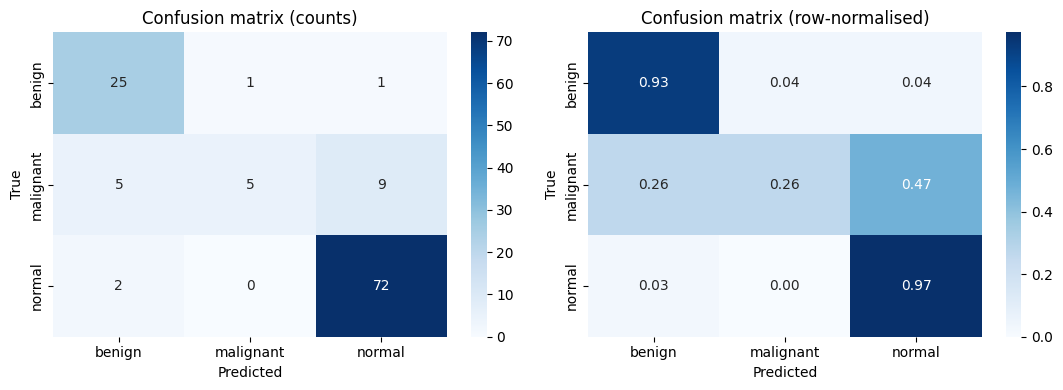

saved -> ./BUS_UCLM_results/xai_BUS_UCLM_resnet50_confusion_matrix.csv
saved -> ./BUS_UCLM_results/xai_BUS_UCLM_resnet50_roc_curves.png


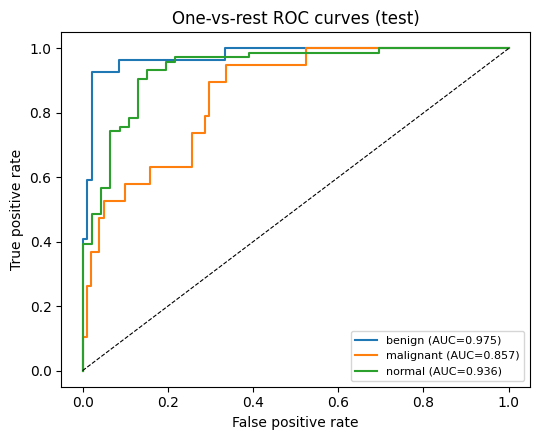

In [6]:
from sklearn.metrics import roc_curve
from sklearn.preprocessing import label_binarize

y_true = test_df.y.values
p_plain = predict_ds(model, test_ds, tta=False)
y_prob = predict_ds(model, test_ds, tta=USE_TTA)          # v5: TTA probabilities are used everywhere below
y_pred = y_prob.argmax(1)
print(f"Test accuracy without TTA: {accuracy_score(y_true, p_plain.argmax(1)):.4f} | with TTA: {accuracy_score(y_true, y_pred):.4f}  (USE_TTA={USE_TTA})")
print(classification_report(y_true, y_pred, target_names=CLASSES, digits=4))
print("Balanced accuracy:", round(balanced_accuracy_score(y_true, y_pred), 4))
rep_df = pd.DataFrame(classification_report(y_true, y_pred, target_names=CLASSES, digits=4, output_dict=True)).T
save_table(rep_df.round(4), f"{os.path.basename(OUT)}_classification_report.csv")

def clf_metrics(idx):
    return [accuracy_score(y_true[idx], y_pred[idx]),
            balanced_accuracy_score(y_true[idx], y_pred[idx]),
            f1_score(y_true[idx], y_pred[idx], average="macro"),
            roc_auc_score(y_true[idx], y_prob[idx], multi_class="ovr", average="macro")]

pt = clf_metrics(np.arange(len(y_true)))
rng_c = np.random.RandomState(SEED)
bs = []
for _ in range(N_BOOT):
    idx = rng_c.randint(0, len(y_true), len(y_true))
    if len(np.unique(y_true[idx])) == len(CLASSES):
        bs.append(clf_metrics(idx))
bs = np.array(bs)
clf_table = pd.DataFrame({"metric": ["accuracy", "balanced accuracy", "macro-F1", "macro OvR AUC"], "value": pt,
                          "ci_low": np.percentile(bs, 2.5, axis=0), "ci_high": np.percentile(bs, 97.5, axis=0)}).round(4)
print(clf_table.to_string(index=False))
clf_table.to_csv(f"{OUT}_classification.csv", index=False)

cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[0])
sns.heatmap(cm / cm.sum(1, keepdims=True), annot=True, fmt=".2f", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[1])
ax[0].set_title("Confusion matrix (counts)"); ax[1].set_title("Confusion matrix (row-normalised)")
for a in ax: a.set_xlabel("Predicted"); a.set_ylabel("True")
plt.tight_layout(); save_fig(f"{os.path.basename(OUT)}_confusion_matrix.png"); plt.show()
save_table(pd.DataFrame(cm, index=CLASSES, columns=CLASSES), f"{os.path.basename(OUT)}_confusion_matrix.csv")

Y1 = label_binarize(y_true, classes=np.arange(len(CLASSES)))
plt.figure(figsize=(5.5, 4.5))
for k, c in enumerate(CLASSES):
    fpr, tpr, _ = roc_curve(Y1[:, k], y_prob[:, k])
    plt.plot(fpr, tpr, label=f"{c} (AUC={auc(fpr, tpr):.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=0.8); plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("One-vs-rest ROC curves (test)"); plt.legend(fontsize=8); plt.tight_layout()
save_fig(f"{os.path.basename(OUT)}_roc_curves.png"); plt.show()


In [7]:
# Optional: 6-fold cross-validation (classification only). Gives a far more reliable accuracy estimate
# than the single 129-image test set. Each fold: test = folds[i], validation = folds[i+1], train = the rest.
# NOTE: models from other folds have seen the fold-0 test images, so they must NOT be ensembled or reused for XAI on fold 0.
if RUN_CV:
    CV_PATH = f"{OUT}_cv6.csv"
    cv_rows = pd.read_csv(CV_PATH).to_dict("records") if os.path.exists(CV_PATH) else []   # v8: resume finished folds
    for i in range(len(folds)):
        if any(int(r["fold"]) == i for r in cv_rows):
            print("fold", i, "already done - skipping"); continue
        j = (i + 1) % len(folds)
        te_i, va_i = df.iloc[folds[i]].reset_index(drop=True), df.iloc[folds[j]].reset_index(drop=True)
        tr_i = df.iloc[np.concatenate([folds[k] for k in range(len(folds)) if k not in (i, j)])].reset_index(drop=True)
        assert not (set(tr_i.group) & set(te_i.group)) and not (set(va_i.group) & set(te_i.group))
        m_, b_, _ = train_model(tr_i, va_i, verbose=0)
        p_ = predict_ds(m_, make_ds(te_i))
        cv_rows.append(dict(fold=i, n_test=len(te_i), accuracy=accuracy_score(te_i.y, p_.argmax(1)),
                            macro_f1=f1_score(te_i.y, p_.argmax(1), average="macro"), bal_acc=balanced_accuracy_score(te_i.y, p_.argmax(1)),
                            macro_auc=roc_auc_score(te_i.y, p_, multi_class="ovr", average="macro")))
        print(cv_rows[-1])
        pd.DataFrame(cv_rows).round(4).to_csv(CV_PATH, index=False)   # v8: save after every fold
        del m_, b_; gc.collect()
    cv_df = pd.DataFrame(cv_rows)
    print(cv_df.round(4).to_string(index=False))
    print(cv_df[["accuracy", "bal_acc", "macro_f1", "macro_auc"]].agg(["mean", "std"]).round(4))
    cv_df.round(4).to_csv(f"{OUT}_cv6.csv", index=False)


## Explainers
All gradient-based methods explain the **logit** of the target class (the predicted class), which avoids vanishing gradients when the softmax saturates. Faithfulness metrics below still measure the change in **probability**. RISE masks fade pixels towards the same neutral gray used by the faithfulness metrics.

In [8]:
def minmax(a):
    a = a - a.min()
    return a / (a.max() + 1e-8)

def make_rise_masks(N, s=7, p1=0.5, seed=SEED):
    rng = np.random.RandomState(seed)
    cell = int(np.ceil(IMG_SIZE / s)); up = (s + 1) * cell
    grid = (rng.rand(N, s, s) < p1).astype("float32")
    masks = np.empty((N, IMG_SIZE, IMG_SIZE), "float32")
    for i in range(N):
        m = cv2.resize(grid[i], (up, up), interpolation=cv2.INTER_LINEAR)
        dx, dy = rng.randint(0, cell, 2)
        masks[i] = m[dx:dx + IMG_SIZE, dy:dy + IMG_SIZE]
    return masks

# data-independent baselines
def random_map(x, cls=None):
    return minmax(cv2.GaussianBlur(np.random.rand(IMG_SIZE, IMG_SIZE).astype("float32"), (0, 0), 15))

_yy, _xx = np.mgrid[:IMG_SIZE, :IMG_SIZE]
CENTER = minmax(np.exp(-((_yy - IMG_SIZE / 2) ** 2 + (_xx - IMG_SIZE / 2) ** 2)
                       / (2 * (IMG_SIZE / 4) ** 2)).astype("float32"))
def center_prior(x, cls=None):
    return CENTER

def make_predictor(m, bs=PRED_BS):
    """Chunked, fixed-signature forward pass -> NumPy probabilities (no retracing, bounded GPU memory)."""
    @tf.function(input_signature=[tf.TensorSpec([None, IMG_SIZE, IMG_SIZE, 3], tf.float32)])
    def fwd(xb):
        return m(xb, training=False)
    def predict(X):
        X = np.asarray(X, "float32")
        return np.concatenate([fwd(tf.constant(X[i:i + bs])).numpy() for i in range(0, len(X), bs)])
    return predict

def make_explainers(m, rise_masks=None):
    """Build all explainers for model m (so the same code can explain randomized copies)."""
    conv_t = m.get_layer(CFG["last_conv"]).output
    logit_t = m.get_layer("logits").output
    gm = models.Model(m.input, [conv_t, logit_t])
    mid_t = m.get_layer(CFG["mid_conv"] if USE_MID_LAYERCAM else CFG["last_conv"]).output
    gm_mid = models.Model(m.input, [mid_t, logit_t])               # v4: LayerCAM source layer
    lm = models.Model(m.input, logit_t)
    predict = make_predictor(m)

    def _cls(x, cls):
        return int(np.argmax(m(x, training=False)[0])) if cls is None else cls

    def _acts_grads(x, cls, gmodel=None):
        gmodel = gmodel or gm
        with tf.GradientTape() as tape:
            conv, lg = gmodel(x, training=False)
            score = lg[:, cls]
        g = tape.gradient(score, conv)
        return conv[0].numpy(), g[0].numpy()                      # (h, w, c) each

    def _finish(cam):
        return minmax(cv2.resize(cam.astype("float32"), (IMG_SIZE, IMG_SIZE)))

    def gradcam(x, cls=None):
        cls = _cls(x, cls); A, G = _acts_grads(x, cls)
        return _finish(np.maximum((A * G.mean((0, 1))).sum(-1), 0))

    def gradcampp(x, cls=None):
        cls = _cls(x, cls); A, G = _acts_grads(x, cls)
        g2, g3 = G ** 2, G ** 3
        den = 2 * g2 + A.sum((0, 1), keepdims=True) * g3
        alpha = g2 / np.where(den != 0, den, 1.0)
        w = (alpha * np.maximum(G, 0)).sum((0, 1))
        return _finish(np.maximum((A * w).sum(-1), 0))

    def layercam(x, cls=None):
        cls = _cls(x, cls); A, G = _acts_grads(x, cls, gm_mid)
        return _finish(np.maximum((np.maximum(G, 0) * A).sum(-1), 0))

    def integrated_gradients(x, cls=None, steps=IG_STEPS):
        cls = _cls(x, cls)
        x = tf.convert_to_tensor(x, tf.float32)
        baseline = tf.constant(GRAY[None], tf.float32)           # neutral gray (model-input space)
        alphas = tf.linspace(0.0, 1.0, steps + 1)
        grads = []
        for i in range(0, steps + 1, IG_CHUNK):          # chunked: backprop through all steps at once is the OOM hot spot
            a = alphas[i:i + IG_CHUNK][:, None, None, None]
            inter = baseline + a * (x - baseline)
            with tf.GradientTape() as tape:
                tape.watch(inter)
                p = lm(inter, training=False)[:, cls]
            grads.append(tape.gradient(p, inter))
        g = tf.concat(grads, 0)
        avg = tf.reduce_mean((g[:-1] + g[1:]) / 2.0, axis=0, keepdims=True)   # trapezoid rule
        attr = tf.reduce_sum(tf.abs(((x - baseline) * avg)[0]), axis=-1).numpy()
        return minmax(cv2.GaussianBlur(attr, (0, 0), 2))

    def rise(x, cls=None):
        cls = _cls(x, cls)
        x0 = np.asarray(x)[0]
        preds = []
        for i in range(0, len(rise_masks), 100):
            mk = rise_masks[i:i + 100, ..., None]
            preds.append(predict(GRAY + (x0 - GRAY) * mk)[:, cls])
        preds = np.concatenate(preds)
        sal = np.tensordot(preds, rise_masks, axes=(0, 0)) / (rise_masks.sum(0) + 1e-8)
        return minmax(sal.astype("float32"))

    ex = {"Grad-CAM": gradcam, "Grad-CAM++": gradcampp, "LayerCAM": layercam,
          "Integrated Gradients": integrated_gradients}
    if rise_masks is not None:
        ex["RISE"] = rise
    ex["Random (baseline)"] = random_map
    ex["Center prior (baseline)"] = center_prior
    return ex

rise_masks = make_rise_masks(N_RISE) if USE_RISE else None
EXPLAINERS = make_explainers(model, rise_masks)
print(list(EXPLAINERS))

['Grad-CAM', 'Grad-CAM++', 'LayerCAM', 'Integrated Gradients', 'RISE', 'Random (baseline)', 'Center prior (baseline)']


## Metrics

In [9]:
predict_probs = make_predictor(model)

def predict_cls_prob(imgs, cls):
    return predict_probs(imgs)[:, cls]

def deletion_insertion(x, cam, cls, steps=20):
    """x: (IMG_SIZE,IMG_SIZE,3) preprocessed. Returns (deletion_auc, insertion_auc, curves)."""
    order = np.argsort(-cam.ravel())
    n = cam.size
    blur = cv2.GaussianBlur(x, (0, 0), 10)
    fr = np.linspace(0, 1, steps + 1)
    del_imgs, ins_imgs = [], []
    for f in fr:
        mask = np.zeros(n, bool); mask[order[:int(f * n)]] = True
        mask = mask.reshape(IMG_SIZE, IMG_SIZE, 1)
        del_imgs.append(np.where(mask, GRAY, x))     # remove most relevant pixels -> neutral gray
        ins_imgs.append(np.where(mask, x, blur))     # reveal most relevant pixels on blurred image
    pd_ = predict_cls_prob(np.stack(del_imgs), cls)
    pi_ = predict_cls_prob(np.stack(ins_imgs), cls)
    return auc(fr, pd_), auc(fr, pi_), (fr, pd_, pi_)

def drop_and_increase(x, cam, cls):
    """Average Drop & Increase-in-Confidence: explanation-masked image vs. original."""
    y = predict_cls_prob(x[None], cls)[0]
    o = predict_cls_prob((GRAY + (x - GRAY) * cam[..., None])[None], cls)[0]   # fade low-relevance pixels to gray
    return max(0.0, y - o) / (y + 1e-8) * 100, float(o > y) * 100

def lesion_mask(paths):
    """Union of all mask files of an image ("|"-separated); all zeros for normal images."""
    m = np.zeros((IMG_SIZE, IMG_SIZE), np.float32)
    for p in str(paths).split("|"):
        if p:
            mm = cv2.imread(p, cv2.IMREAD_COLOR)
            if mm is None:
                continue
            mm = cv2.resize(mm, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_NEAREST)
            # Red and green RGB-mask pixels both represent lesion regions.
            m = np.maximum(m, (mm.max(axis=-1) > 50).astype(np.float32))
    return m

def localization(cam, mask):
    """Returns energy, relative energy (1 = chance), rank acc, pointing, IoU@0.5, map AUROC (0.5 = chance), top-K IoU."""
    area = mask.mean()
    energy = (cam * mask).sum() / (cam.sum() + 1e-8)                      # relevance mass inside lesion
    K = int(mask.sum())
    top = np.argsort(-cam.ravel())[:K]
    rank_acc = mask.ravel()[top].mean()                                   # top-K pixels inside lesion
    pointing = float(mask.ravel()[np.argmax(cam.ravel())] > 0)            # max point inside lesion
    binm = cam > 0.5
    iou = (binm & (mask > 0)).sum() / ((binm | (mask > 0)).sum() + 1e-8)
    map_auc = roc_auc_score(mask.ravel() > 0, cam.ravel()) if 0 < K < mask.size else np.nan
    topm = np.zeros(cam.size, bool); topm[top] = True                    # v4: IoU of the top-K pixels (K = lesion size)
    mk = mask.ravel() > 0
    iou_k = (topm & mk).sum() / ((topm | mk).sum() + 1e-8)
    return energy, energy / area, rank_acc, pointing, iou, map_auc, iou_k

def stability(explainer, x, cls, base_cam, n=N_NOISE, sigma=5.0):
    """Mean Spearman correlation between the map and maps from noisy inputs
    (Gaussian noise with sigma=5 on the raw 0-255 pixel scale). Noisy copies that change the
    predicted class are skipped. Returns (mean correlation, fraction of copies kept)."""
    rs = []
    for _ in range(n):
        xn = x + (np.random.normal(0, sigma, x.shape) * SCALE).astype("float32")
        if int(np.argmax(model(xn[None], training=False)[0])) != cls:
            continue
        c2 = explainer(xn[None], cls)
        rs.append(spearmanr(base_cam.ravel(), c2.ravel())[0])
    kept = len(rs) / n                                  # fraction of noisy copies with unchanged prediction
    return (np.nanmean(rs) if rs else np.nan), kept

## Run quantitative XAI evaluation on the BUS-UCLM test split

In [10]:
if N_EVAL_PER_CLASS is None:
    eval_df = test_df.copy()
else:
    eval_df = pd.concat([g.sample(min(len(g), N_EVAL_PER_CLASS), random_state=SEED)
                         for _, g in test_df.groupby("label")]).reset_index(drop=True)
eval_df["img_id"] = np.arange(len(eval_df))
print(len(eval_df), "images;", eval_df.label.value_counts().to_dict())

def with_oom_retry(fn, *args, tries=2):
    """Retry once after freeing Python garbage if the GPU runs out of memory; re-raise if it persists."""
    for t in range(tries):
        try:
            return fn(*args)
        except tf.errors.ResourceExhaustedError:
            if t == tries - 1:
                raise
            print("  OOM - collecting garbage and retrying")
            gc.collect(); time.sleep(1)

CKPT = os.path.join(BASE_DIR, f"xai_checkpoint_{BACKBONE}.pkl")     # v8: progress is saved every 5 images
SIG = (BACKBONE, len(eval_df), N_RISE, N_NOISE, N_NOISE_RISE, IMG_SIZE, tuple(EXPLAINERS))
records, curves = [], {k: {"del": [], "ins": []} for k in EXPLAINERS}
if os.path.exists(CKPT):
    try:
        _sig, _rec, _cur = pickle.load(open(CKPT, "rb"))
        if _sig == SIG:
            records, curves = _rec, _cur
            print(f"Resuming from checkpoint: {len({r['img_id'] for r in records})} images already done")
        else:
            print("Checkpoint is from a different configuration - starting fresh (delete", CKPT, "to silence this)")
    except Exception as e:
        print("Could not read checkpoint, starting fresh:", e)
done = {r["img_id"] for r in records}
t0 = time.time()
for i, r in eval_df.iterrows():
    if r["img_id"] in done:
        continue
    x = preprocess_input(load_img(r["path"]).numpy())
    cls = int(np.argmax(model(x[None], training=False)[0]))
    mask = lesion_mask(r["mask_path"])
    has_lesion = mask.sum() > 0
    for name, fn in EXPLAINERS.items():
        cam = with_oom_retry(fn, x[None], cls)
        d_auc, i_auc, (fr, pdel, pins) = deletion_insertion(x, cam, cls)
        avg_drop, inc_conf = drop_and_increase(x, cam, cls)
        if has_lesion:
            energy, rel_energy, rank_acc, pointing, iou, map_auc, iou_k = localization(cam, mask)
        else:                                  # normal image: no lesion -> localization undefined
            energy = rel_energy = rank_acc = pointing = iou = map_auc = iou_k = np.nan
        n_stab = N_NOISE_RISE if name == "RISE" else N_NOISE
        stab, stab_kept = with_oom_retry(stability, fn, x, cls, cam, n_stab)
        curves[name]["del"].append(pdel); curves[name]["ins"].append(pins)
        records.append(dict(img_id=r.img_id, method=name, true=r.label, pred=CLASSES[cls],
                            correct=bool(cls == r.y),
                            deletion_auc=d_auc, insertion_auc=i_auc, avg_drop=avg_drop, inc_conf=inc_conf,
                            lesion_energy=energy, rel_energy=rel_energy, rank_acc=rank_acc,
                            pointing=pointing, iou=iou, iou_topk=iou_k, map_auc=map_auc,
                            stability=stab, stab_kept=stab_kept, lesion_area_frac=mask.mean(),
                            group=r.group))
    gc.collect()
    if (i + 1) % 5 == 0:
        pickle.dump((SIG, records, curves), open(CKPT, "wb"))
    if (i + 1) % 10 == 0:
        print(f"{i+1}/{len(eval_df)} images done ({time.time()-t0:.0f}s)")
        try:
            mi = tf.config.experimental.get_memory_info("GPU:0")
            print(f"   GPU memory: current {mi['current']/2**20:.0f} MB, peak {mi['peak']/2**20:.0f} MB")
        except Exception:
            pass

pickle.dump((SIG, records, curves), open(CKPT, "wb"))
res = pd.DataFrame(records)
res.to_csv(f"{OUT}_per_image.csv", index=False)

76 images; {'normal': 30, 'benign': 27, 'malignant': 19}
10/76 images done (318s)
   GPU memory: current 523 MB, peak 8025 MB
20/76 images done (616s)
   GPU memory: current 523 MB, peak 8025 MB
30/76 images done (900s)
   GPU memory: current 523 MB, peak 8025 MB
40/76 images done (1169s)
   GPU memory: current 523 MB, peak 8025 MB
50/76 images done (1505s)
   GPU memory: current 523 MB, peak 8025 MB
60/76 images done (1884s)
   GPU memory: current 523 MB, peak 8025 MB
70/76 images done (2244s)
   GPU memory: current 523 MB, peak 8025 MB


## Results with bootstrap confidence intervals

In [11]:
metric_cols = ["deletion_auc", "insertion_auc", "avg_drop", "inc_conf",
               "lesion_energy", "rel_energy", "rank_acc", "pointing", "iou", "iou_topk", "map_auc", "stability"]
LOWER_BETTER = {"deletion_auc", "avg_drop"}
METHODS = list(res.method.unique())
rng_b = np.random.RandomState(SEED)

def boot_ci(v, g, n=N_BOOT):
    """Cluster bootstrap: resamples duplicate GROUPS (not single images), because near-duplicate
    images in the test set are not independent. Mean = mean over all images in resampled groups."""
    v = np.asarray(v, float); g = np.asarray(g)
    ok = ~np.isnan(v); v, g = v[ok], g[ok]
    if len(v) == 0:
        return np.nan, np.nan, np.nan, 0
    _, inv = np.unique(g, return_inverse=True)
    s = np.bincount(inv, weights=v); c = np.bincount(inv).astype(float)
    idx = rng_b.randint(0, len(s), (n, len(s)))
    bm = s[idx].sum(1) / c[idx].sum(1)
    lo, hi = np.percentile(bm, [2.5, 97.5])
    return v.mean(), lo, hi, len(v)

num_rows = []
for mth in METHODS:
    sub = res[res.method == mth]
    for mc in metric_cols:
        mean, lo, hi, n = boot_ci(sub[mc], sub["group"])
        num_rows.append(dict(method=mth, metric=mc, mean=mean, ci_low=lo, ci_high=hi, n=n))
ci_df = pd.DataFrame(num_rows)
ci_df.round(4).to_csv(f"{OUT}_summary_ci.csv", index=False)
save_table(res.groupby("method")[metric_cols].mean().round(4), f"{os.path.basename(OUT)}_mean_by_method.csv")

pretty = ci_df.assign(txt=lambda d: d.apply(lambda r: f"{r['mean']:.3f} [{r.ci_low:.3f}, {r.ci_high:.3f}]", axis=1)) \
              .pivot(index="metric", columns="method", values="txt").loc[metric_cols, METHODS]
print("=== Mean [95% bootstrap CI]  (localization metrics: benign/malignant images only) ===")
print(pretty.to_string())
save_table(pretty, f"{os.path.basename(OUT)}_summary_mean_ci_formatted.csv")

lesion_rows = res[res.lesion_area_frac > 0]
print("\nChance levels -> lesion_energy / rank_acc / pointing ~", round(lesion_rows.lesion_area_frac.mean(), 3),
      "| rel_energy = 1 | map_auc = 0.5")
print("Stability: mean fraction of noisy copies kept (prediction unchanged):",
      res.groupby("method").stab_kept.mean().round(3).to_dict())
print("Better = LOWER for:", sorted(LOWER_BETTER), "| HIGHER for all other metrics")

print("\n=== Per true class (mean) ===")
per_class = res.groupby(["method", "true"])[metric_cols].mean().round(4)
print(per_class); per_class.to_csv(f"{OUT}_per_class.csv")

print("\n=== Correct vs incorrect predictions (mean) ===")
per_corr = res.groupby(["method", "correct"])[metric_cols].mean().round(4)
print(per_corr); per_corr.to_csv(f"{OUT}_correct_vs_incorrect.csv")
print("\n#correctly / incorrectly classified eval images:",
      res.drop_duplicates("img_id").correct.value_counts().to_dict())

saved -> ./BUS_UCLM_results/xai_BUS_UCLM_resnet50_mean_by_method.csv
=== Mean [95% bootstrap CI]  (localization metrics: benign/malignant images only) ===
method                        Grad-CAM               Grad-CAM++                 LayerCAM     Integrated Gradients                     RISE        Random (baseline)  Center prior (baseline)
metric                                                                                                                                                                                      
deletion_auc      0.433 [0.383, 0.484]     0.426 [0.371, 0.482]     0.495 [0.383, 0.601]     0.473 [0.415, 0.535]     0.381 [0.318, 0.450]     0.442 [0.305, 0.589]     0.425 [0.362, 0.498]
insertion_auc     0.636 [0.595, 0.658]     0.662 [0.632, 0.684]     0.512 [0.456, 0.557]     0.573 [0.523, 0.610]     0.636 [0.571, 0.700]     0.445 [0.338, 0.566]     0.621 [0.589, 0.661]
avg_drop       30.526 [20.502, 41.317]  28.210 [21.333, 35.005]  52.334 [42.465, 62.313] 

In [12]:
# Paired Wilcoxon signed-rank tests (per image), Holm-corrected within each (metric, reference) family
def holm(p):
    p = np.asarray(p, float); order = np.argsort(p); mm = len(p)
    adj = np.empty(mm); running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (mm - rank) * p[i]); adj[i] = min(1.0, running)
    return adj

def paired_table(metric, refs=("Random (baseline)", "Grad-CAM")):
    wide = res.pivot(index="img_id", columns="method", values=metric)
    out = []
    for ref in refs:
        if ref not in wide.columns:
            continue
        names, ps, diffs = [], [], []
        for mth in wide.columns:
            if mth == ref:
                continue
            d = wide[[mth, ref]].dropna()
            diff = d[mth] - d[ref]
            p = 1.0 if (len(d) < 5 or np.allclose(diff, 0)) else wilcoxon(d[mth], d[ref]).pvalue
            names.append(mth); ps.append(p); diffs.append(diff.mean())
        for mth, dfm, pa in zip(names, diffs, holm(ps)):
            out.append(dict(metric=metric, method=mth, vs=ref, mean_diff=dfm, p_holm=pa))
    return pd.DataFrame(out)

tests = pd.concat([paired_table(mc) for mc in metric_cols], ignore_index=True)
tests["sig(p<0.05)"] = tests.p_holm < 0.05
tests.round(4).to_csv(f"{OUT}_paired_tests.csv", index=False)
key = ["deletion_auc", "insertion_auc", "rel_energy", "map_auc", "pointing", "stability"]
print(tests[tests.metric.isin(key)].round(4).to_string(index=False))
print("mean_diff = method minus reference (for deletion_auc / avg_drop a NEGATIVE difference is better)")

       metric                  method                vs  mean_diff  p_holm  sig(p<0.05)
 deletion_auc Center prior (baseline) Random (baseline)    -0.0171  0.6464        False
 deletion_auc                Grad-CAM Random (baseline)    -0.0085  0.9028        False
 deletion_auc              Grad-CAM++ Random (baseline)    -0.0159  0.9028        False
 deletion_auc    Integrated Gradients Random (baseline)     0.0318  0.9028        False
 deletion_auc                LayerCAM Random (baseline)     0.0531  0.9028        False
 deletion_auc                    RISE Random (baseline)    -0.0603  0.1049        False
 deletion_auc Center prior (baseline)          Grad-CAM    -0.0086  0.4772        False
 deletion_auc              Grad-CAM++          Grad-CAM    -0.0074  0.7135        False
 deletion_auc    Integrated Gradients          Grad-CAM     0.0402  0.4478        False
 deletion_auc                LayerCAM          Grad-CAM     0.0616  0.0657        False
 deletion_auc                   

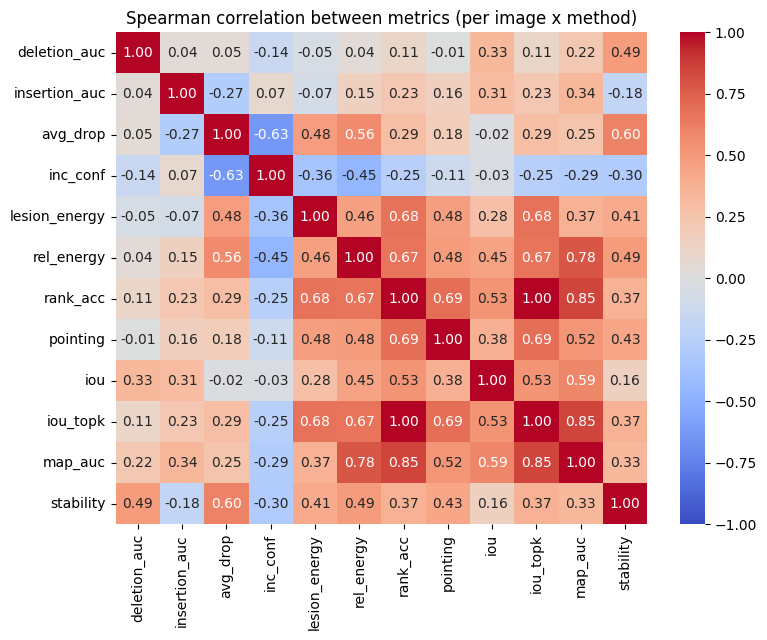

=== Method rank per metric (1 = best) ===
                         deletion_auc  insertion_auc  avg_drop  inc_conf  lesion_energy  rel_energy  rank_acc  pointing  iou  iou_topk  map_auc  stability
method                                                                                                                                                    
Grad-CAM                            4              3         5         3              2           2         3         4    2         3        3          6
Grad-CAM++                          3              1         4         5              3           3         2         4    1         2        2          4
LayerCAM                            7              6         7         6              4           4         5         2    7         5        5          2
Integrated Gradients                6              5         6         6              1           1         1         1    5         1        1          3
RISE                        

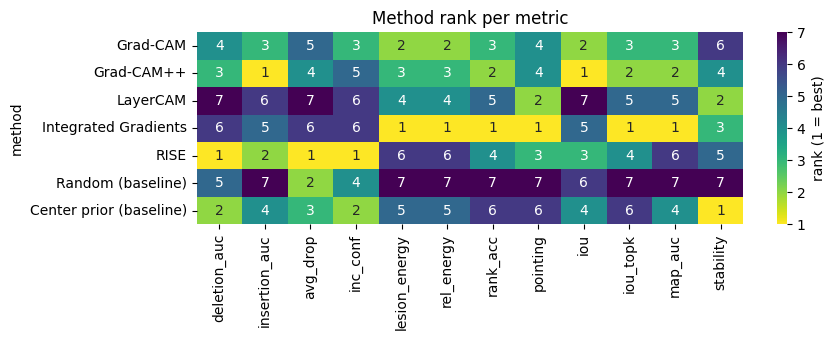

In [13]:
# Do the metrics agree? (real explainers only; baselines excluded)
real = res[~res.method.str.contains("baseline")]
corr = real[metric_cols].corr(method="spearman")
plt.figure(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Spearman correlation between metrics (per image x method)")
plt.tight_layout(); plt.savefig(f"{OUT}_metric_agreement.png", dpi=200); plt.show()

# Method ranking per metric (1 = best)
means = res.groupby("method")[metric_cols].mean().loc[METHODS]
ranks = pd.DataFrame({mc: means[mc].rank(ascending=(mc in LOWER_BETTER)) for mc in metric_cols})
print("=== Method rank per metric (1 = best) ===")
print(ranks.astype(int).to_string())
ranks.to_csv(f"{OUT}_method_ranks.csv")
plt.figure(figsize=(9, 3.5))
sns.heatmap(ranks.astype(int), annot=True, fmt="d", cmap="viridis_r", cbar_kws={"label": "rank (1 = best)"})
plt.title("Method rank per metric"); plt.tight_layout(); save_fig(f"{os.path.basename(OUT)}_method_ranks.png"); plt.show()

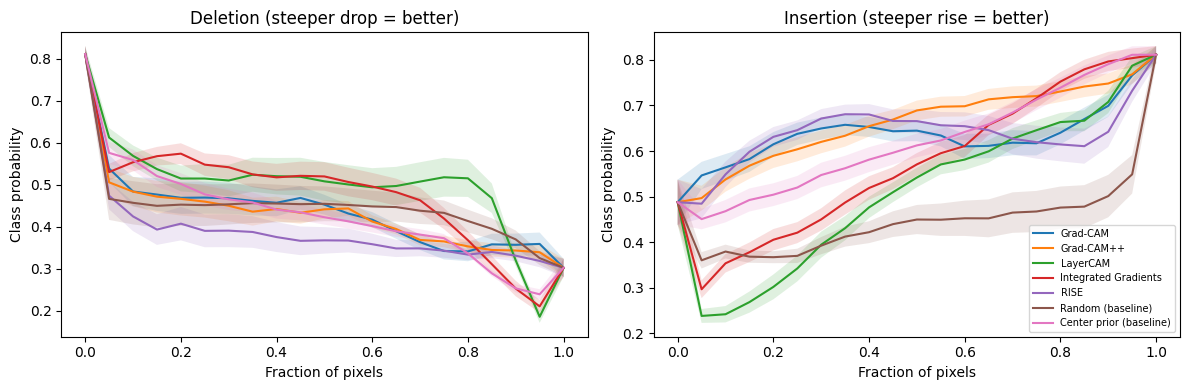

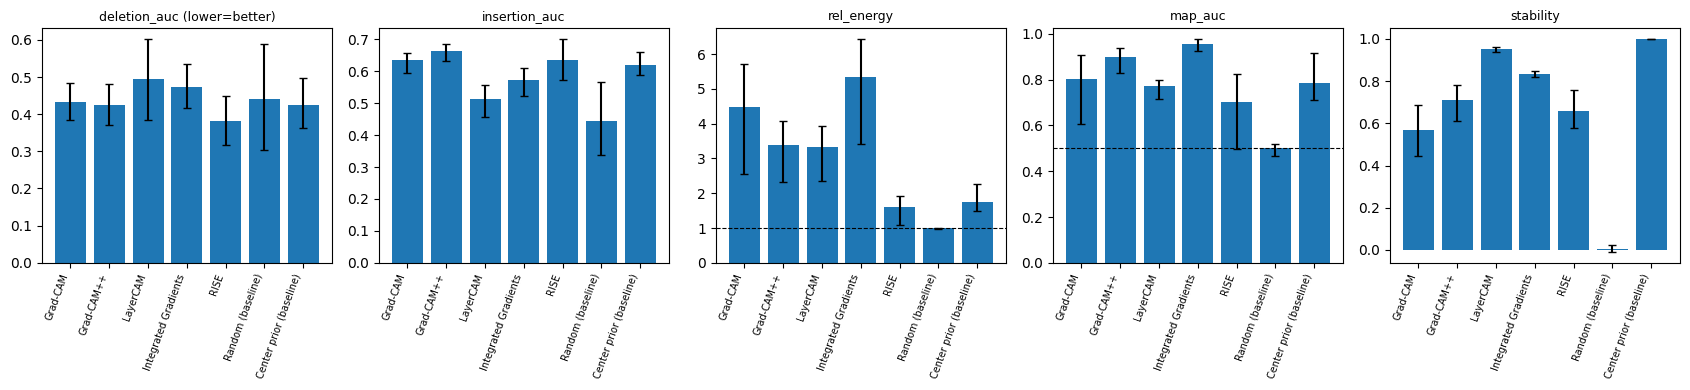

In [14]:
fr = np.linspace(0, 1, 21)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name in EXPLAINERS:
    for k, a in zip(["del", "ins"], ax):
        arr = np.array(curves[name][k]); mu = arr.mean(0)
        a.plot(fr, mu, label=name)
        a.fill_between(fr, mu - arr.std(0) / np.sqrt(len(arr)), mu + arr.std(0) / np.sqrt(len(arr)), alpha=0.15)
ax[0].set_title("Deletion (steeper drop = better)"); ax[1].set_title("Insertion (steeper rise = better)")
for a in ax:
    a.set_xlabel("Fraction of pixels"); a.set_ylabel("Class probability")
ax[1].legend(fontsize=7)
plt.tight_layout(); plt.savefig(f"{OUT}_deletion_insertion_curves.png", dpi=200); plt.show()

# Bar chart of key metrics with 95% CIs
plot_m = ["deletion_auc", "insertion_auc", "rel_energy", "map_auc", "stability"]
fig, axs = plt.subplots(1, len(plot_m), figsize=(3.4 * len(plot_m), 4), sharey=False)
for a, mc in zip(axs, plot_m):
    s = ci_df[ci_df.metric == mc].set_index("method").loc[METHODS]
    a.bar(range(len(METHODS)), s["mean"], yerr=[s["mean"] - s.ci_low, s.ci_high - s["mean"]], capsize=3)
    a.set_xticks(range(len(METHODS))); a.set_xticklabels(METHODS, rotation=70, ha="right", fontsize=7)
    a.set_title(mc + (" (lower=better)" if mc in LOWER_BETTER else ""), fontsize=9)
    if mc == "rel_energy": a.axhline(1, ls="--", c="k", lw=0.8)
    if mc == "map_auc": a.axhline(0.5, ls="--", c="k", lw=0.8)
plt.tight_layout(); plt.savefig(f"{OUT}_key_metrics_ci.png", dpi=200); plt.show()

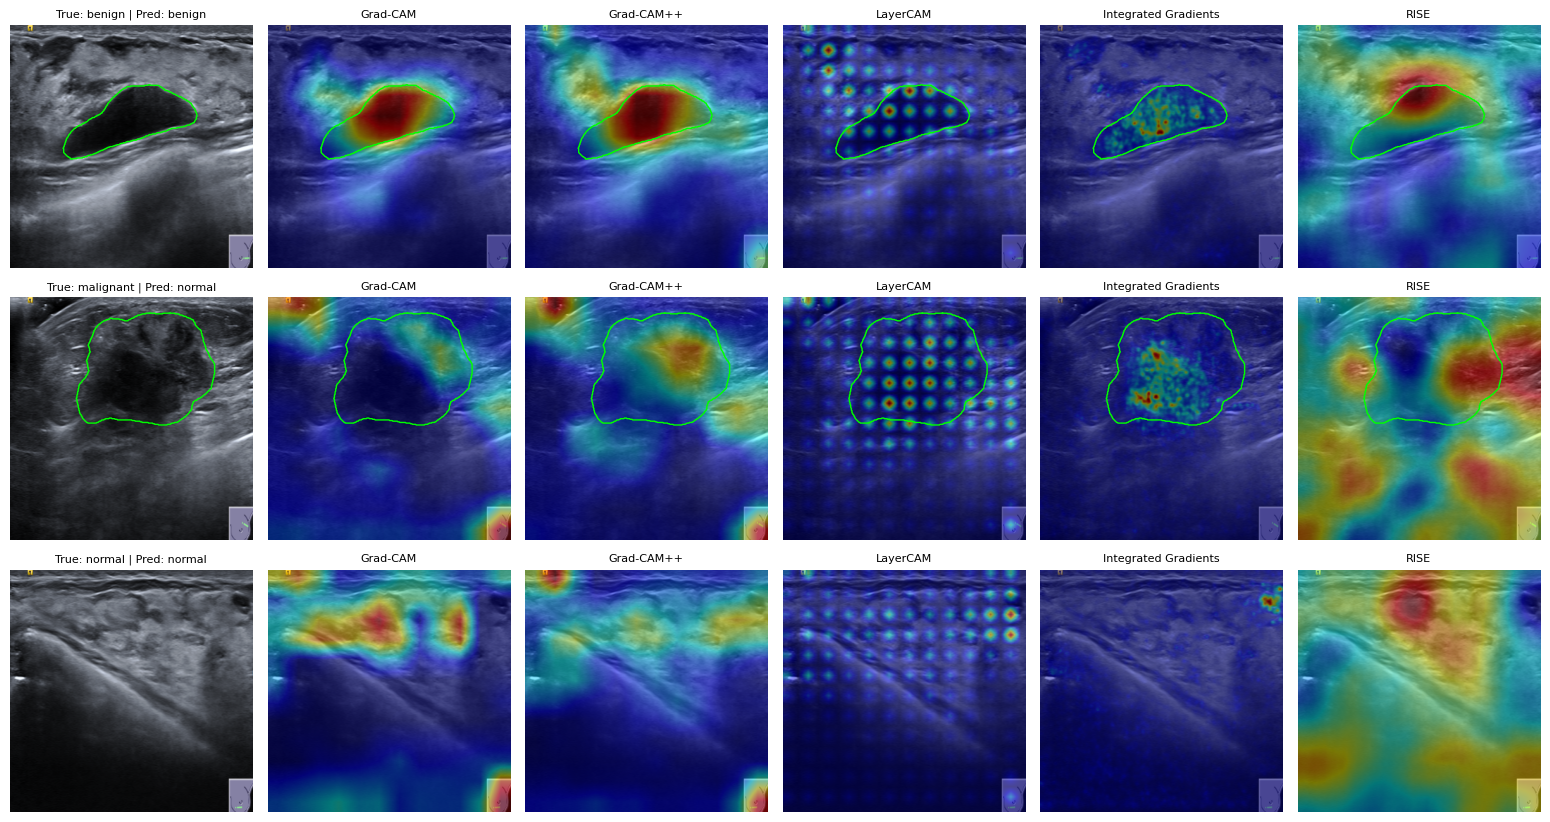

In [15]:
# Qualitative examples: one image per true class (green contour = lesion mask)
show = [m_ for m_ in EXPLAINERS if "baseline" not in m_]
fig, axs = plt.subplots(len(CLASSES), len(show) + 1, figsize=(2.6 * (len(show) + 1), 2.8 * len(CLASSES)))
for row, c in enumerate(CLASSES):
    r = eval_df[eval_df["label"] == c].iloc[0]
    raw = load_img(r["path"]).numpy().astype("uint8")
    x = preprocess_input(load_img(r["path"]).numpy())
    cls = int(np.argmax(model(x[None], training=False)[0]))
    mk = lesion_mask(r["mask_path"])
    panels = [("True: %s | Pred: %s" % (c, CLASSES[cls]), raw)]
    for name in show:
        m_ = EXPLAINERS[name](x[None], cls)
        heat = cv2.applyColorMap((m_ * 255).astype("uint8"), cv2.COLORMAP_JET)[..., ::-1]
        panels.append((name, (0.55 * raw + 0.45 * heat).astype("uint8")))
    for a, (t, im) in zip(axs[row], panels):
        a.imshow(im); a.set_title(t, fontsize=8); a.axis("off")
        if mk.max() > 0:
            a.contour(mk, levels=[0.5], colors="lime", linewidths=1)
plt.tight_layout(); plt.savefig(f"{OUT}_qualitative.png", dpi=200); plt.show()

## Sanity check: model-parameter randomization
If an explanation really depends on what the model learned, re-initializing the weights must destroy it. We compare the map of the trained model with the map of (a) a model whose classifier head is re-initialized and (b) a fully re-initialized model, for the **same target class**. Spearman correlation close to 0 means the method passes. A method that stays highly correlated is acting like an edge or image detector rather than a model explanation.

                                           mean                                            std                    
variant              all weights re-initialized head re-initialized all weights re-initialized head re-initialized
method                                                                                                            
Grad-CAM                                  0.144               0.325                      0.156               0.258
Grad-CAM++                                0.124               0.958                      0.173               0.015
Integrated Gradients                      0.618               0.806                      0.088               0.061
LayerCAM                                  0.827               0.952                      0.053               0.017
RISE                                      0.156               0.174                      0.277               0.261
saved -> ./BUS_UCLM_results/xai_BUS_UCLM_resnet50_sanity_randomization_raw.csv
s

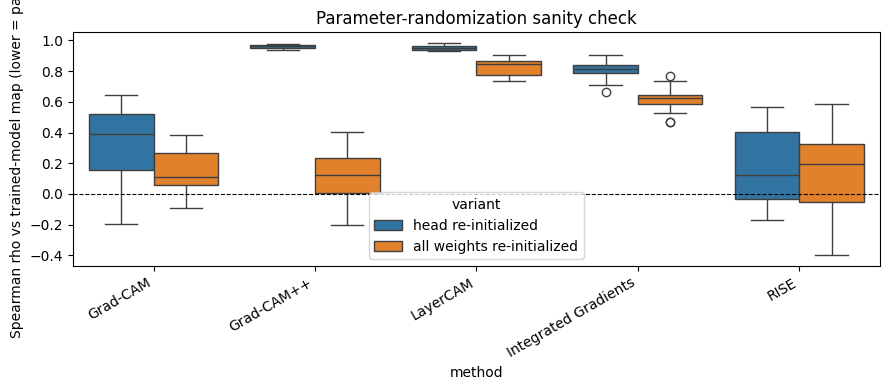

In [16]:
sanity_pool = eval_df[eval_df.label != "normal"]
sanity_df = sanity_pool.sample(min(N_SANITY, len(sanity_pool)), random_state=SEED)

fresh = models.clone_model(model)                         # same architecture, random weights
base_names = {l.name for l in model.layers[:-5]}   # head = GAP, Dense, Dropout, logits, Softmax (last 5 layers)
head_rand = models.clone_model(model)
head_rand.set_weights(model.get_weights())
for l in model.layers:
    if l.name not in base_names and l.weights:
        head_rand.get_layer(l.name).set_weights(fresh.get_layer(l.name).get_weights())

gc.collect()
variants = {"head re-initialized": make_explainers(head_rand, rise_masks),
            "all weights re-initialized": make_explainers(fresh, rise_masks)}
real_methods = [k for k in EXPLAINERS if "baseline" not in k]
srows = []
for _, r in sanity_df.iterrows():
    x = preprocess_input(load_img(r["path"]).numpy())
    cls = int(np.argmax(model(x[None], training=False)[0]))
    for mth in real_methods:
        ref = EXPLAINERS[mth](x[None], cls)
        for vname, ex in variants.items():
            rho = spearmanr(ref.ravel(), ex[mth](x[None], cls).ravel())[0]
            srows.append(dict(method=mth, variant=vname, rho=rho))
sanity = pd.DataFrame(srows)
sanity_tab = sanity.groupby(["method", "variant"]).rho.agg(["mean", "std"]).round(3).unstack("variant")
print(sanity_tab.to_string())
sanity_tab.to_csv(f"{OUT}_sanity_randomization.csv")
save_table(sanity.round(4), f"{os.path.basename(OUT)}_sanity_randomization_raw.csv", index=False)
plt.figure(figsize=(9, 4))
sns.boxplot(data=sanity, x="method", y="rho", hue="variant"); plt.axhline(0, c="k", lw=0.8, ls="--")
plt.xticks(rotation=30, ha="right"); plt.ylabel("Spearman rho vs trained-model map (lower = passes)")
plt.title("Parameter-randomization sanity check"); plt.tight_layout()
save_fig(f"{os.path.basename(OUT)}_sanity_randomization.png"); plt.show()

## Optional backbone comparison (BUS-UCLM only)

In [17]:
# Compare backbone runs from BUS-UCLM only
files = sorted(glob.glob(os.path.join(OUT_DIR, "xai_BUS_UCLM_*_per_image.csv")))
if len(files) > 1:
    allres = pd.concat([pd.read_csv(f).assign(backbone=os.path.basename(f)[len("xai_BUS_UCLM_"):-len("_per_image.csv")]) for f in files])
    cmp_tab = allres.groupby(["backbone", "method"])[["deletion_auc", "insertion_auc", "rel_energy", "map_auc", "pointing", "stability"]].mean().round(3)
    print(cmp_tab.to_string())
    save_table(cmp_tab, "xai_BUS_UCLM_backbone_comparison.csv")
else:
    print("Only one BUS-UCLM backbone result found:", files)


Only one BUS-UCLM backbone result found: ['./BUS_UCLM_results/xai_BUS_UCLM_resnet50_per_image.csv']


## Package every table and figure into one folder and download it
All `.csv` tables and `.png` figures are in `BUS_UCLM_results/`. This cell also bundles all tables into a single Excel workbook, zips the folder and starts the download automatically (you can re-run it at any time, e.g. after a partial run).

In [18]:
import shutil, glob
# 1) all CSV tables -> one Excel workbook (one sheet per table)
try:
    with pd.ExcelWriter(os.path.join(OUT_DIR, "ALL_TABLES.xlsx")) as xw:
        for f in sorted(glob.glob(os.path.join(OUT_DIR, "*.csv"))):
            if os.path.basename(f) == "BUS_UCLM_dataset_labels.csv":
                continue                                    # too long and path-specific
            sheet = os.path.splitext(os.path.basename(f))[0].replace("xai_BUS_UCLM_", "")[-31:]
            pd.read_csv(f).to_excel(xw, sheet_name=sheet, index=False)
except Exception as e:
    print("Excel bundle skipped:", e)

# 2) list what is in the folder
print("Files in", OUT_DIR, ":")
for f in sorted(os.listdir(OUT_DIR)):
    print(f"  {f}  ({os.path.getsize(os.path.join(OUT_DIR, f))/1024:.0f} KB)")

# 3) zip and download automatically
zip_path = shutil.make_archive("/content/BUS_UCLM_results", "zip", OUT_DIR)
print("Zip created:", zip_path)
try:
    from google.colab import files
    files.download(zip_path)                                 # browser download starts automatically
except ImportError:
    print("Not running in Colab - find the zip next to the notebook:", os.path.abspath(zip_path))


Files in ./BUS_UCLM_results :
  ALL_TABLES.xlsx  (111 KB)
  BUS_UCLM_dataset_labels.csv  (72 KB)
  BUS_UCLM_split_class_counts.csv  (0 KB)
  BUS_UCLM_splits.csv  (44 KB)
  xai_BUS_UCLM_resnet50_classification.csv  (0 KB)
  xai_BUS_UCLM_resnet50_classification_report.csv  (0 KB)
  xai_BUS_UCLM_resnet50_confusion_matrix.csv  (0 KB)
  xai_BUS_UCLM_resnet50_confusion_matrix.png  (76 KB)
  xai_BUS_UCLM_resnet50_correct_vs_incorrect.csv  (2 KB)
  xai_BUS_UCLM_resnet50_deletion_insertion_curves.png  (325 KB)
  xai_BUS_UCLM_resnet50_key_metrics_ci.png  (118 KB)
  xai_BUS_UCLM_resnet50_mean_by_method.csv  (1 KB)
  xai_BUS_UCLM_resnet50_method_ranks.csv  (1 KB)
  xai_BUS_UCLM_resnet50_method_ranks.png  (107 KB)
  xai_BUS_UCLM_resnet50_metric_agreement.png  (309 KB)
  xai_BUS_UCLM_resnet50_paired_tests.csv  (8 KB)
  xai_BUS_UCLM_resnet50_per_class.csv  (2 KB)
  xai_BUS_UCLM_resnet50_per_image.csv  (91 KB)
  xai_BUS_UCLM_resnet50_qualitative.png  (4925 KB)
  xai_BUS_UCLM_resnet50_roc_curves.png  (

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>